<a href="https://colab.research.google.com/github/Eswar-10/LSTM/blob/main/SMS_Spam_Detection_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Cell 1: Import libraries

import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Libraries imported successfully!


In [1]:

from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    print(filename)


Saving spam.csv to spam.csv

Uploaded files:
spam.csv


In [5]:
# Cell 3: Find and inspect uploaded CSV files

import pandas as pd

csv_files = [
    name for name in uploaded.keys()
    if name.lower().endswith(".csv")
]

if not csv_files:
    raise FileNotFoundError(
        "No CSV uploaded. Upload the SMS dataset CSV."
    )

for filename in csv_files:
    print("\nFile:", filename)

    # Try reading with latin-1 encoding to prevent decoding issues with special characters
    try:
        preview = pd.read_csv(filename, nrows=5, encoding='utf-8')
    except UnicodeDecodeError:
        preview = pd.read_csv(filename, nrows=5, encoding='latin-1')

    print("Columns:", preview.columns.tolist())
    display(preview.head(3))


File: spam.csv
Columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN


In [23]:

# Cell 4: Clean and select 2,000 SMS messages

import pandas as pd
from sklearn.model_selection import train_test_split

# Load the correct SMS dataset
df = pd.read_csv(csv_files[0], encoding="latin-1")

# Keep only the actual SMS label and message columns
df = df[["v1", "v2"]].copy()
df.columns = ["label", "text"]

# Remove missing and duplicate messages
df = df.dropna(subset=["label", "text"])
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["text"] = df["text"].astype(str).str.strip()
df = df[df["label"].isin(["ham", "spam"])]
df = df[df["text"] != ""]
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

# Select exactly 2,000 messages, preserving class proportions
df, _ = train_test_split(
    df,
    train_size=2000,
    random_state=42,
    stratify=df["label"]
)

# HAM = 0, SPAM = 1
df["label"] = df["label"].map({"ham": 0, "spam": 1}).astype(int)

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())
display(df.head())


Dataset shape: (2000, 2)

Class distribution:
label
0    1751
1     249
Name: count, dtype: int64


,label,text
1047,0,Aight ill get on fb in a couple minutes
3685,0,I havent add Ì_ yet right..
4117,1,As one of our registered subscribers u can ent...
1430,0,I think its far more than that but find out. C...
2028,0,Lara said she can loan me &lt;#&gt; .


In [11]:

# Cell 6: Tokenization and padded numerical sequences

import tensorflow as tf

VOCAB_SIZE = 10000
MAX_SEQUENCE_LENGTH = 100

vectorize_layer = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=MAX_SEQUENCE_LENGTH,
    standardize="lower_and_strip_punctuation"
)

# Learn vocabulary only from training messages
vectorize_layer.adapt(
    tf.data.Dataset.from_tensor_slices(X_train).batch(32)
)

# Convert text into padded numerical sequences
X_train_seq = vectorize_layer(
    tf.constant(X_train)
).numpy()

X_test_seq = vectorize_layer(
    tf.constant(X_test)
).numpy()

print("Vocabulary size:", len(vectorize_layer.get_vocabulary()))
print("Training shape:", X_train_seq.shape)
print("Testing shape:", X_test_seq.shape)
print("Example sequence:", X_train_seq[0][:20])


Vocabulary size: 4560
Training shape: (1600, 100)
Testing shape: (400, 100)
Example sequence: [ 215   18 3887    9    5  220  539   24   58   11   46  197   19    6
  177    0    0    0    0    0]


In [12]:

# Cell 7: Create LSTM deep learning model

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(MAX_SEQUENCE_LENGTH,)),
    tf.keras.layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64,
        mask_zero=True
    ),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,137 (2.58 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:

# Cell 8: Train the LSTM model

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_seq,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

print("Training completed!")


Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.8516 - loss: 0.5269 - val_accuracy: 0.8687 - val_loss: 0.3422
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9531 - loss: 0.1624 - val_accuracy: 0.9531 - val_loss: 0.1901
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9945 - loss: 0.0429 - val_accuracy: 0.9750 - val_loss: 0.1238
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9984 - loss: 0.0173 - val_accuracy: 0.9688 - val_loss: 0.1162
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9984 - loss: 0.0107 - val_accuracy: 0.9719 - val_loss: 0.1114
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9992 - loss: 0.0063 - val_accuracy: 0.9719 - val_loss: 0.1207
Epoch 7/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.0027 - val_accuracy: 0.9750 - val_loss: 0.1352
Epoch 8/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 0.0019 - val_accuracy: 0.9719 - val_

In [14]:

# Cell 9: Model evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_prob = model.predict(X_test_seq, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["HAM", "SPAM"],
    zero_division=0
))


Accuracy : 0.985
Precision: 0.9782608695652174
Recall   : 0.9
F1-score : 0.9375

Classification Report:
              precision    recall  f1-score   support

         HAM       0.99      1.00      0.99       350
        SPAM       0.98      0.90      0.94        50

    accuracy                           0.98       400
   macro avg       0.98      0.95      0.96       400
weighted avg       0.98      0.98      0.98       400



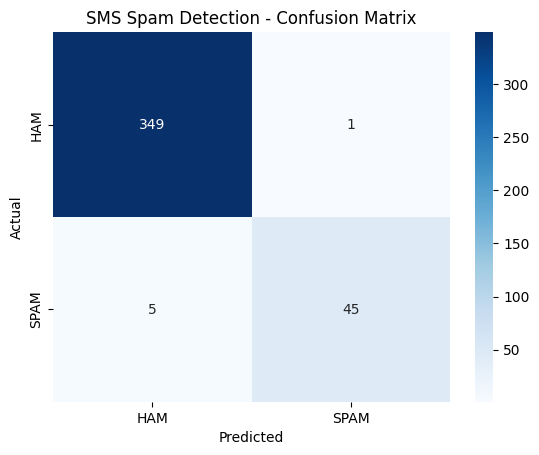

In [15]:

# Cell 10: Confusion matrix

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["HAM", "SPAM"],
    yticklabels=["HAM", "SPAM"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.show()


In [16]:

# Cell 11: Test custom SMS messages

def predict_sms(message):
    sequence = vectorize_layer(
        tf.constant([message])
    )

    probability = float(
        model.predict(sequence, verbose=0)[0][0]
    )

    label = "SPAM" if probability >= 0.5 else "HAM"

    print("Message:", message)
    print("Prediction:", label)
    print("Spam probability:", round(probability * 100, 2), "%")
    print("-" * 50)

predict_sms("Congratulations! You won a free prize. Claim now!")
predict_sms("Hi, are we meeting for lunch today?")
predict_sms("URGENT! Claim your cash reward now!")
predict_sms("Please call me when you reach home.")


Message: Congratulations! You won a free prize. Claim now!
Prediction: SPAM
Spam probability: 99.3 %
--------------------------------------------------
Message: Hi, are we meeting for lunch today?
Prediction: HAM
Spam probability: 0.04 %
--------------------------------------------------
Message: URGENT! Claim your cash reward now!
Prediction: SPAM
Spam probability: 96.6 %
--------------------------------------------------
Message: Please call me when you reach home.
Prediction: HAM
Spam probability: 0.18 %
--------------------------------------------------


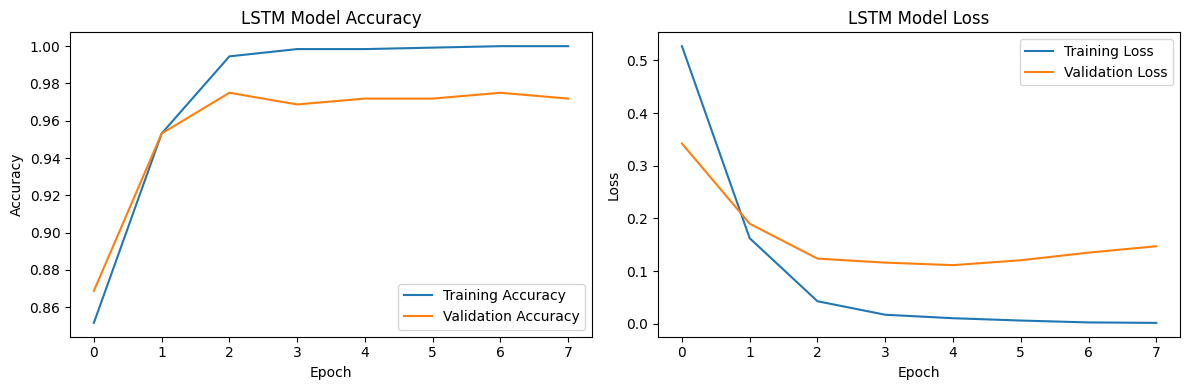

In [17]:

# Cell 12: Visualize training performance

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [19]:

# Cell 13: Save the complete SMS Spam Detection model

import tensorflow as tf

# Combine text preprocessing and trained LSTM
full_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(), dtype=tf.string),
    vectorize_layer,
    model
])

# Save the complete model
full_model.save("/content/sms_spam_detection.keras")

print("Complete SMS Spam Detection model saved successfully!")


Complete SMS Spam Detection model saved successfully!


In [20]:

from google.colab import files

files.download("/content/sms_spam_detection.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:

# Cell 15: Reload and test the saved model

loaded_model = tf.keras.models.load_model(
    "/content/sms_spam_detection.keras"
)

test_sms = tf.constant([
    "Congratulations! You won a free prize. Claim now!",
    "Hi, are we meeting for lunch today?"
])

probabilities = loaded_model.predict(test_sms, verbose=0).ravel()

for message, probability in zip(test_sms.numpy(), probabilities):
    label = "SPAM" if probability >= 0.5 else "HAM"
    print("Message:", message.decode("utf-8"))
    print("Prediction:", label)
    print("Spam probability:", round(float(probability) * 100, 2), "%")
    print("-" * 40)


Message: Congratulations! You won a free prize. Claim now!
Prediction: SPAM
Spam probability: 99.3 %
----------------------------------------
Message: Hi, are we meeting for lunch today?
Prediction: HAM
Spam probability: 0.04 %
----------------------------------------


Accuracy : 0.985
Precision: 0.9783
Recall   : 0.9
F1-score : 0.9375


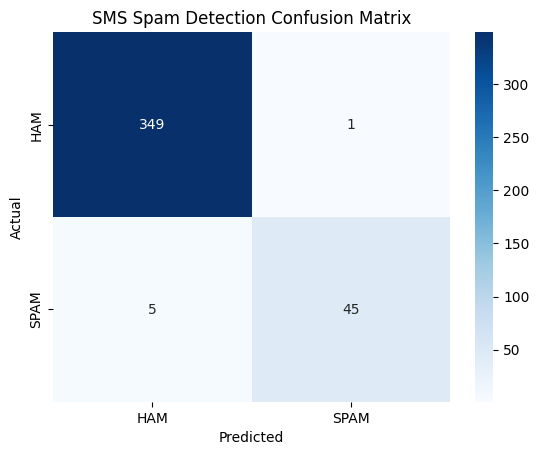

In [22]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Predict on the held-out test set
y_prob = model.predict(X_test_seq, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["HAM", "SPAM"],
    yticklabels=["HAM", "SPAM"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SMS Spam Detection Confusion Matrix")
plt.show()
